In [4]:
# libraries
import re
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import transformers
from transformers import AutoTokenizer
from schema import RawPost
from langchain_huggingface import HuggingFaceEmbeddings

In [5]:
PROJECT_ROOT = Path.cwd() if (Path.cwd()/'schema.py').exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [6]:
RAW_PATH = PROJECT_ROOT / "data" / "raw.jsonl"
pd.set_option('display.max_colwidth', 100)
transformers.logging.set_verbosity_error()
print("Reading: ", RAW_PATH)

Reading:  /Users/irenebusah/Desktop/ai-engineer-4-ds/lessons/llm-engineering/projects/opportunity-finder/data/raw.jsonl


In [7]:
# loading and validating the data
with open(RAW_PATH, encoding='utf-8') as file:
    posts = [RawPost.model_validate_json(line) for line in file if line.strip()]

dataframe = pd.DataFrame([post.model_dump() for post in posts])
dataframe['thread'] = dataframe['thread_title'].str.extract(r"\((.+)\)")[0]
print(f"{len(dataframe)} posts loaded and validated")
dataframe[["post_id", "thread", "author", "n_replies", "text"]].head(5)

2278 posts loaded and validated


,post_id,thread,author,n_replies,text
0,49922584,October 2026,mwest1066,1,PrairieLearn (Remote US) — Full-Stack Software Engineer — TypeScript / Postgres / React / AI\n\n...
1,49922593,October 2026,shepherd-eng,0,"Shepherd (Series B) | ONSITE | San Francisco, CA & New York City, NY\n\nAt Shepherd, we're pursu..."
2,49922609,October 2026,mcintyem,0,"Sidekick Labs | Senior SWE, R&D Engineer, Intelligence Engineer | REMOTE (US Timezones) | Full-t..."
3,49922615,October 2026,eterps,0,"Open Education Applications / Neon | Senior/Lead Platform & DevOps Engineer, Senior Frontend Eng..."
4,49922616,October 2026,pagnos,0,"PAGNOS | Cloud Engineer, AWS Serverless (TypeScript/Node.js) | REMOTE (Germany) | Full-time | €7..."


In [8]:
# overview: threads, authors, replies
threads = (
    dataframe.groupby(['thread_id', 'thread']).size().rename("posts")
    .reset_index().sort_values("thread_id")
)

threads

,thread_id,thread,posts
0,47219668,March 2026,317
1,47601859,April 2026,329
2,47975571,May 2026,318
3,48357725,June 2026,313
4,48747976,July 2026,259
5,49156683,August 2026,227
6,49522897,September 2026,249
7,49922569,October 2026,266


In [9]:
threads_by_author = dataframe.groupby("author")["thread_id"].nunique()

print("distinct authors: ", dataframe["author"].nunique())
print(f"authors who posted in more than one thread: {(threads_by_author > 1).sum()} of {len(threads_by_author)}")
print(f"posts with zero replies: {(dataframe['n_replies'] == 0).mean():.0%}")

distinct authors:  1400
authors who posted in more than one thread: 420 of 1400
posts with zero replies: 76%


In [10]:
# checking companies that repost every month
def show(row, n=700):
    print(f"--- {row.url} | {row.thread} ---")
    print(row.text[:n], "\n")


top_author = threads_by_author.idxmax()
print(f"Author with the most threads: {top_author} ({threads_by_author.max()} threads)\n")

for _, row in dataframe[dataframe['author'] == top_author].sort_values("thread_id").head(5).iterrows():
    show(row, 400)

Author with the most threads: BatonTrucking (8 threads)

--- https://news.ycombinator.com/item?id=47250582 | March 2026 ---
Baton | Senior Software Engineer - Full Stack, Technical Lead / Software Engineer - Infrastructure, Data Platform | San Francisco, CA (Hybrid) | Full-Time

Baton (baton.io) is Ryder's in-house product development group focused on harnessing emerging technologies to redefine transportation and logistics. With $10B in freight under management, our technology reaches every part of the U.S. economy.

 

--- https://news.ycombinator.com/item?id=47603601 | April 2026 ---
Baton | Senior Software Engineer - Full Stack, Technical Lead / Software Engineer - Infrastructure, Data Platform | San Francisco, CA (Hybrid) | Full-Time

Baton (baton.io) is Ryder's in-house product development group focused on harnessing emerging technologies to redefine transportation and logistics. With $10B in freight under management, our technology reaches every part of the U.S. economy.

 

---

In [11]:
dataframe['n_chars'] = dataframe['text'].str.len()
dataframe['n_chars'].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame('characters per post')

,characters per post
count,2278.0
mean,1138.0
std,568.0
min,6.0
50%,1074.0
90%,1845.0
99%,2846.0
max,4429.0


In [12]:
BASE_MODEL = 'meta-llama/Llama-3.2-3B'
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

In [13]:
TOKENIZERS = {
    "embed": EMBED_MODEL,
    "llm": BASE_MODEL
}

tokenizers = {label: AutoTokenizer.from_pretrained(name) for label, name in TOKENIZERS.items()}

In [14]:
# tokenizers

In [15]:
sample = dataframe['text'].iloc[0][:160]
print("TEXT: ", sample, "\n")

for label, tok in tokenizers.items():
    ids = tok(sample, add_special_tokens=False)['input_ids']
    print(f"{label} -> {len(ids)} tokens")
    print(tok.convert_ids_to_tokens(ids)[:30], "\n")

TEXT:  PrairieLearn (Remote US) — Full-Stack Software Engineer — TypeScript / Postgres / React / AI

PrairieLearn (https://www.prairielearn.com) is an open-source asse 

embed -> 47 tokens
['prairie', '##lea', '##rn', '(', 'remote', 'us', ')', '—', 'full', '-', 'stack', 'software', 'engineer', '—', 'types', '##cript', '/', 'post', '##gre', '##s', '/', 'react', '/', 'ai', 'prairie', '##lea', '##rn', '(', 'https', ':'] 

llm -> 44 tokens
['P', 'ra', 'irie', 'Learn', 'Ġ(', 'Remote', 'ĠUS', ')', 'ĠâĢĶ', 'ĠFull', '-', 'Stack', 'ĠSoftware', 'ĠEngineer', 'ĠâĢĶ', 'ĠTypeScript', 'Ġ/', 'ĠPost', 'gres', 'Ġ/', 'ĠReact', 'Ġ/', 'ĠAI', 'ĊĊ', 'P', 'ra', 'irie', 'Learn', 'Ġ(', 'https'] 



In [16]:
texts = dataframe["text"].tolist()
for label, tok in tokenizers.items():
    dataframe[f"tokens_{label}"] = [len(ids) for ids in tok(texts, add_special_tokens=False)["input_ids"]]

token_cols = [f"tokens_{label}" for label in TOKENIZERS]
dataframe[token_cols].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0)

,tokens_embed,tokens_llm
count,2278.0,2278.0
mean,277.0,256.0
std,137.0,126.0
min,1.0,1.0
50%,259.0,241.0
90%,445.0,413.0
95%,533.0,490.0
99%,718.0,652.0
max,1177.0,1037.0


In [17]:
ratio = dataframe["n_chars"] / dataframe["tokens_llm"]
print(f"characters per token (LLM tokenizer): median {ratio.median():.1f}")
print("total tokens in the dataset:")
print(dataframe[token_cols].sum().to_string())

characters per token (LLM tokenizer): median 4.5
total tokens in the dataset:
tokens_embed    630323
tokens_llm      583580


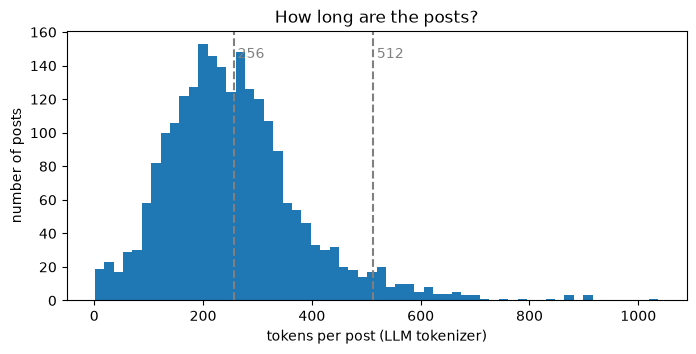

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(dataframe["tokens_llm"], bins=60)
for limit in (256, 512):
    ax.axvline(limit, linestyle="--", color="grey")
    ax.text(limit, ax.get_ylim()[1] * 0.9, f" {limit}", color="grey")
ax.set_xlabel("tokens per post (LLM tokenizer)")
ax.set_ylabel("number of posts")
ax.set_title("How long are the posts?")
plt.show()

In [19]:
limits = [256, 512, 1024, 2048]
over = pd.DataFrame(
    {label: [(dataframe[f"tokens_{label}"] > n).mean() * 100 for n in limits] for label in TOKENIZERS},
    index=[f"> {n} tokens" for n in limits],
).round(1)
over.columns = [f"% of posts ({c} tokenizer)" for c in over.columns]
over

,% of posts (embed tokenizer),% of posts (llm tokenizer)
> 256 tokens,51.1,44.9
> 512 tokens,5.8,4.3
> 1024 tokens,0.0,0.0
> 2048 tokens,0.0,0.0


In [20]:
checks = {
    "mentions remote":         r"\bremote\b",
    "mentions onsite":         r"\bon-?site\b",
    "mentions hybrid":         r"\bhybrid\b",
    "mentions visa":           r"\bvisa\b",
    "mentions relocation":     r"relocat",
    "US-only wording":         r"\bUS[- ]only\b|\bUSA? only\b|\bUS citizen|\bwork authori[sz]ation\b",
    "salary-like figure":      r"[$€£]\s?\d|\b\d{2,3}\s?k\b",
    "contains an email":       r"[\w.+-]+(?:@|\s?\[at\]\s?)[\w-]+(?:\.|\s?\[dot\]\s?)[\w.-]+",
    "contains a URL":          r"https?://",
    "mentions a deadline":     r"\bdeadline\b|\bapply by\b|\bapplications? close",
    "mentions internship":     r"\bintern(?:ship)?s?\b",
}
rates = {name: dataframe["text"].str.contains(pat, case=False, regex=True).mean() * 100
         for name, pat in checks.items()}
first_line = dataframe["text"].str.split("\n").str[0]
rates["first line uses '|' separators"] = first_line.str.contains("|", regex=False).mean() * 100

pd.Series(rates).round(1).sort_values(ascending=False).to_frame("% of posts")

,% of posts
first line uses '|' separators,89.9
contains a URL,85.3
mentions remote,53.5
salary-like figure,39.8
mentions onsite,31.8
contains an email,29.8
mentions hybrid,21.1
mentions visa,5.5
mentions relocation,4.0
US-only wording,3.7


In [21]:
print("=== 5 random posts ===\n")
for _, row in dataframe.sample(5, random_state=42).iterrows():
    show(row)

=== 5 random posts ===

--- https://news.ycombinator.com/item?id=48749101 | July 2026 ---
Ecosmic | Senior DevOps Engineer | Remote (Italy) | €50,000–€60,000

Ecosmic is on a mission to reduce threat exposure in space by building software for Space Situational Awareness. To achieve this, we built a team of flight dynamics engineers and computer scientists to build & package in-house algorithms into easy-to-use, reliable, and secure products. As an example, our platform recently allowed us to identify a series of close approaches in GEO involving Russia's Luch/Olymp-2 and a Western telecommunications satellite, possibly attributed to SIGINT activity.

We're hiring a Senior DevOps Engineer (mid-level candidates are welcome too!) to aid the effort of unlocking on-premises deployment 

--- https://news.ycombinator.com/item?id=49533419 | September 2026 ---
Robotics and AI Institute | Software Engineering Intern | ONSITE (Zürich, Switzerland) | Internship | No visa sponsorship

We're hiring 

In [22]:
print("=== 5 shortest posts ===\n")
for _, row in dataframe.nsmallest(5, "n_chars").iterrows():
    print(f"--- {row.url} | {row.n_chars} chars ---\n{row.text}\n")

=== 5 shortest posts ===

--- https://news.ycombinator.com/item?id=48434880 | 6 chars ---
REMOTE

--- https://news.ycombinator.com/item?id=47741050 | 6 chars ---
Remote

--- https://news.ycombinator.com/item?id=48362210 | 8 chars ---
nelalsal

--- https://news.ycombinator.com/item?id=49159899 | 9 chars ---
[flagged]

--- https://news.ycombinator.com/item?id=49163435 | 9 chars ---
[flagged]



In [23]:
more_checks = {
    "senior / staff / lead / principal": r"\b(?:senior|staff|lead|principal|sr\.?)\b",
    "junior / entry-level / new grad":   r"\b(?:junior|entry[- ]level|new[- ]grad(?:uate)?s?|recent graduates?)\b",
    "worldwide / work from anywhere":    r"\bworldwide\b|\bwork from anywhere\b|\banywhere in the world\b|\bremote\s?\(\s?(?:world|global|anywhere)",
    "Africa / Rwanda / Kigali":          r"\bafrica\b|\brwanda\b|\bkigali\b",
    "EMEA / timezone wording":           r"\bEMEA\b|\bCET\b|\bUTC\s?[+-]\s?\d|\btime ?zones?\b",
}
rates2 = {name: dataframe["text"].str.contains(pat, case=False, regex=True).mean() * 100
          for name, pat in more_checks.items()}
pd.Series(rates2).round(1).to_frame("% of posts")

,% of posts
senior / staff / lead / principal,55.5
junior / entry-level / new grad,3.1
worldwide / work from anywhere,4.7
Africa / Rwanda / Kigali,0.2
EMEA / timezone wording,6.2
